# Imports

##### standard python libraries

In [1]:
import polars as pl
import adbc_driver_postgresql.dbapi as adbc_api
import re

import cartopy.crs as ccrs
import cartopy.feature as cfeature
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon
import matplotlib.cm as cm

In [2]:
import warnings
warnings.filterwarnings('ignore')

##### Custom Libraries

In [3]:
import psql_utilities as psql_utl

### Set Paths

In [4]:
### path to configuration file of database
path_conf_file = './../../config/database.ini'

### Database Connection

In [5]:
db_config = psql_utl.load_config(path_conf_file)
### connect to the databse (polars adbc)
conn = adbc_api.connect(db_config['db_uri'])

## Retrieve simulation run parameters of PS scenarios

In this notebook, we use simulation run parameters associated with PS-type scenarios to plot the slip distribution over the fault mesh.

### setup

##### read query from file

In [6]:
query_params_ps = open("./query_params_ps.sql", "r")
query_params_ps = query_params_ps.read()

### query result

##### run query with polars

In [7]:
df_sr_params_ps = pl.read_database_uri(query_params_ps,engine='connectorx',uri=db_config['db_uri'],partition_num=6)
df_sr_params_ps

sr_id,sr_path,scen_name,fk_sr_id,seismicity_type,magnitude,manning_coeff,mesh_fault_bc_lon,mesh_fault_bc_lat,mesh_fault_rake_uniform,mesh_fault_slip_avg,mesh_fault,mesh_slip
str,str,str,str,str,f64,f64,f64,f64,f64,f64,str,list[f64]
"""sr_225423""","""CT-SR_M100/PS_001/E02020N3739E…","""E02020N3739E02658N3366-PS-Str_…","""sr_225423""","""PS""",8.71,0.01,22.17,35.48,90.0,8.046897,"""MULTIPOLYGON Z (((20.6197 35.6…","[0.421, 0.225, … 22.058]"
"""sr_225555""","""CT-SR_M100/PS_001/E01964N3926E…","""E01964N3926E02184N3685-PS-Mur_…","""sr_225555""","""PS""",7.74,0.01,20.81,37.77,90.0,1.004608,"""MULTIPOLYGON Z (((20.2765 38.1…","[0.884, 0.885, … 0.964]"
"""sr_225737""","""CT-SR_M100/PS_001/E02113N3823E…","""E02113N3823E02873N3483-PS-Str_…","""sr_225737""","""PS""",8.09,0.01,22.66,36.71,90.0,3.083,"""MULTIPOLYGON Z (((22.5629 37.4…","[3.083, 3.083, … 3.083]"
"""sr_226377""","""CT-SR_M100/PS_001/E02020N3739E…","""E02020N3739E02658N3366-PS-Str_…","""sr_226377""","""PS""",8.37,0.01,22.82,34.51,90.0,4.703623,"""MULTIPOLYGON Z (((23.4596 33.9…","[0.211, 0.031, … 9.544]"
"""sr_226399""","""CT-SR_M100/PS_001/E02113N3823E…","""E02113N3823E02873N3483-PS-Str_…","""sr_226399""","""PS""",7.92,0.01,22.44,36.59,90.0,1.51417,"""MULTIPOLYGON Z (((22.7544 37.0…","[1.211, 1.209, … 2.033]"
…,…,…,…,…,…,…,…,…,…,…,…,…
"""sr_253110""","""CT-SR_M100/PS_001/E02020N3739E…","""E02020N3739E02658N3366-PS-Str_…","""sr_253110""","""PS""",8.71,0.01,21.44,36.68,90.0,7.232971,"""MULTIPOLYGON Z (((20.0258 36.8…","[1.822, 0.181, … 0.66]"
"""sr_253252""","""CT-SR_M100/PS_001/E02020N3739E…","""E02020N3739E02658N3366-PS-Str_…","""sr_253252""","""PS""",8.71,0.01,20.92,36.79,90.0,7.49792,"""MULTIPOLYGON Z (((19.5887 37.2…","[1.106, 0.487, … 0.124]"
"""sr_253350""","""CT-SR_M100/PS_001/E01849N3766E…","""E01849N3766E02950N3220-PS-Mur_…","""sr_253350""","""PS""",8.61,0.01,20.61,36.28,90.0,5.29672,"""MULTIPOLYGON Z (((19.5887 37.2…","[0.684, 0.388, … 0.418]"


### PS Mesh Fault

##### We compute mesh faults stats

Additionally one can use the SR parameters to select a mesh faults from a subset of PS events

In [8]:
pattern = '\(\(([^(].*?)\)\)'
df_mesh_fault = df_sr_params_ps.select('scen_name','mesh_fault','mesh_slip')\
                                .with_columns(pl.col('mesh_fault').map_elements(lambda x: re.findall(pattern, x),return_dtype=pl.List(pl.String)))\
                                .explode(pl.col('mesh_fault'),'mesh_slip')\
                                .select(pl.col('mesh_fault').alias('mesh_triangle'),pl.col('mesh_slip').alias('slip'))
#
df_mesh_stats = df_mesh_fault.group_by('mesh_triangle')\
                             .agg(pl.col('slip').sum().alias('total_slip'),
                                  pl.col('slip').max().alias('max_slip'),
                                  pl.col('slip').mean().alias('mean_slip'),
                                  pl.col('slip').len().alias('num_triangles')
                                )\
                             .with_columns(pl.col('mesh_triangle').map_elements(lambda x: [(float(item.split(' ')[0]),float(item.split(' ')[1])) for item in x.split(',')],return_dtype=pl.Object))
df_mesh_stats

mesh_triangle,total_slip,max_slip,mean_slip,num_triangles
object,f64,f64,f64,u32
"[(15.8975, 37.3571), (16.0404, 37.3963), (15.9111, 37.4845), (15.8975, 37.3571)]",4589.716,10.761,3.347714,1371
"[(16.7479, 37.6267), (16.5061, 37.6139), (16.6347, 37.5252), (16.7479, 37.6267)]",15158.419,23.252,6.337132,2392
"[(23.5823, 35.6271), (23.4481, 35.6501), (23.4944, 35.5331), (23.5823, 35.6271)]",68251.574,32.535,5.725323,11921
"[(16.2654, 37.6004), (16.5061, 37.6139), (16.3775, 37.7024), (16.2654, 37.6004)]",12180.594,20.521,5.792009,2103
"[(31.0334, 35.1658), (31.1389, 35.0395), (31.218, 35.1476), (31.0334, 35.1658)]",55.499,5.692,2.312458,24
…,…,…,…,…
"[(23.2406, 34.3415), (23.4067, 34.3131), (23.3339, 34.4458), (23.2406, 34.3415)]",39587.828,20.761,4.224955,9370
"[(31.358, 35.3641), (31.434, 35.4716), (31.2525, 35.49), (31.358, 35.3641)]",75.733,5.692,3.155542,24
"[(27.1752, 34.6551), (27.313, 34.6786), (27.2065, 34.7588), (27.1752, 34.6551)]",1353.444,14.93,1.799793,752


##### Plot Slip Distribution on Mesh Faults

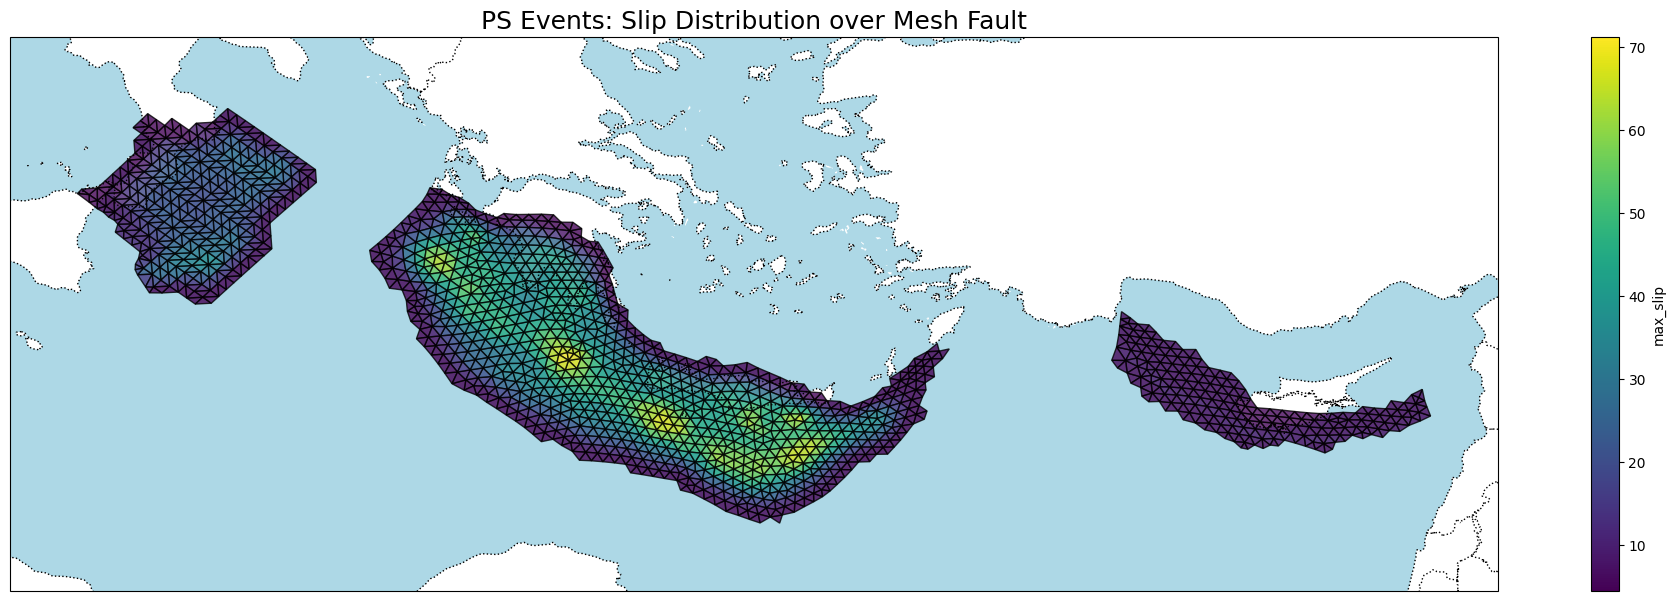

In [9]:
slip_variables = 'max_slip'

fig, ax = plt.subplots(
            figsize=(24, 12),
            subplot_kw={'projection': ccrs.PlateCarree()}
        )

ax.add_feature(cfeature.COASTLINE,linestyle=':')
ax.add_feature(cfeature.BORDERS,linestyle=':')
#ax.add_feature(cfeature.LAND, facecolor='lightgray')
ax.add_feature(cfeature.OCEAN, facecolor='lightblue')

### define color map
norm = plt.Normalize(df_mesh_stats[slip_variables].min(), df_mesh_stats[slip_variables].max())
cmap = cm.viridis

min_lon = 39
max_lon = -6.5
min_lat = 45
max_lat = 30
for triangle,num_occ in zip(df_mesh_stats['mesh_triangle'],df_mesh_stats[slip_variables]):
    #
    triangle_poly = Polygon([(item[0],item[1]) for item in triangle], edgecolor='black', facecolor=cmap(norm(num_occ)),alpha=0.8)
    ax.add_patch(triangle_poly)
    #
    list_lons_t = [pnt[0] for pnt in triangle]
    list_lats_t = [pnt[1] for pnt in triangle]
    min_lon_t = min(list_lons_t)
    max_lon_t = max(list_lons_t)
    min_lat_t = min(list_lats_t)
    max_lat_t = max(list_lats_t)
    #
    min_lon = min(min_lon,min_lon_t)
    max_lon = max(max_lon,max_lon_t)
    min_lat = min(min_lat,min_lat_t)
    max_lat = max(max_lat,max_lat_t)

#ax.set_extent([-6.5, 39, 30, 45])
ax.set_extent([min_lon-1, max_lon+1, min_lat-1, max_lat+1])
ax.set_title("PS Events: Slip Distribution over Mesh Fault", fontsize=18)

sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
#sm.set_array([])
fig.colorbar(sm, ax=ax, orientation='vertical', label=slip_variables,shrink=0.6, pad=0.05)